# 3 · Cross-asset spillovers (Diebold-Yilmaz)
A VAR(2) on daily returns, decomposed with the **generalised forecast-error variance decomposition** (10-day horizon), measures how much of each asset's forecast uncertainty comes from shocks to *other* assets.
* **Total spillover index:** the average share of variance explained by other assets, a measure of market connectedness.
* **Net spillover:** transmitted minus received; positive means the asset is a net *source* of shocks.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from covidmkt import data as D
px = D.load_prices("../data/prices.csv")          # refresh: python scripts/fetch_data.py
rets = D.log_returns(px)
def shade(ax):
    for p, (s, e) in D.PERIODS.items():
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=D.PERIOD_COLORS[p], alpha=0.07)
print(f"{len(px):,} trading days, {px.shape[1]} series, {px.index[0]:%Y-%m-%d} -> {px.index[-1]:%Y-%m-%d}")
from covidmkt import spillover as S

1,761 trading days, 15 series, 2018-01-02 -> 2024-12-31


In [2]:
sel = ["SPY", "EEM", "HYG", "TLT", "GC=F", "USO", "DX-Y.NYB", "BTC-USD"]
r = rets[sel] * 100
tbl, total = S.spillover_table(r, lags=2, horizon=10)
names = D.label(sel)
show = tbl.copy(); show.index = names + ["TO others", "NET"]; show.columns = names + ["FROM others"]
print(f"Full-sample total spillover index: {total:.1f}%")
show.round(1)

Full-sample total spillover index: 37.8%


,US large caps,EM equities,High yield,Long Treasuries,Gold,Crude oil,US dollar,Bitcoin,FROM others
US large caps,40.2,23.2,25.0,1.4,0.5,4.0,2.1,3.6,59.8
EM equities,24.6,41.9,18.0,1.1,1.5,4.2,5.5,3.2,58.1
High yield,26.5,18.3,42.4,0.3,1.6,3.0,5.2,2.7,57.6
Long Treasuries,3.1,1.5,0.8,83.4,4.9,2.5,3.5,0.3,16.6
Gold,0.8,2.9,2.6,4.9,74.4,0.7,12.5,1.2,25.6
Crude oil,7.6,7.7,5.3,2.5,0.7,75.0,0.3,0.8,25.0
US dollar,4.9,9.2,9.4,3.2,10.4,0.5,60.8,1.5,39.2
Bitcoin,6.7,5.5,4.5,0.1,1.1,0.6,1.7,79.8,20.2
TO others,74.3,68.3,65.7,13.6,20.7,15.5,30.7,13.4,37.8
NET,14.5,10.3,8.1,-3.0,-4.9,-9.5,-8.5,-6.9,NaN


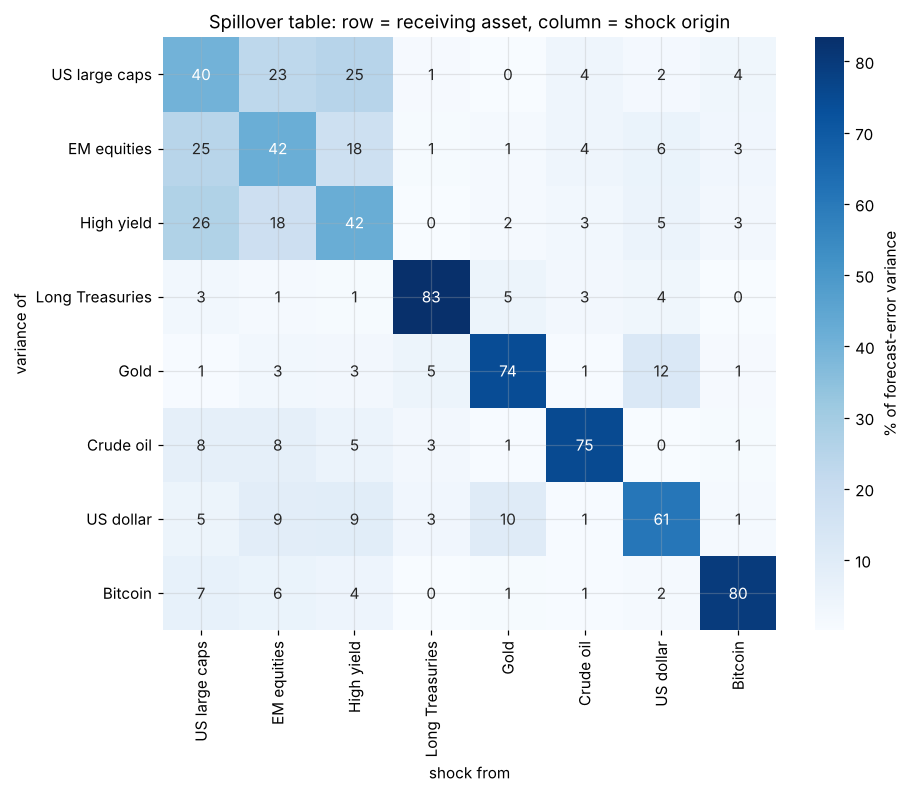

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(show.iloc[:len(sel), :len(sel)], annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% of forecast-error variance"})
ax.set_title("Spillover table: row = receiving asset, column = shock origin"); ax.set_xlabel("shock from"); ax.set_ylabel("variance of")
plt.savefig(IMG / "spillover_table.png", bbox_inches="tight"); plt.show()

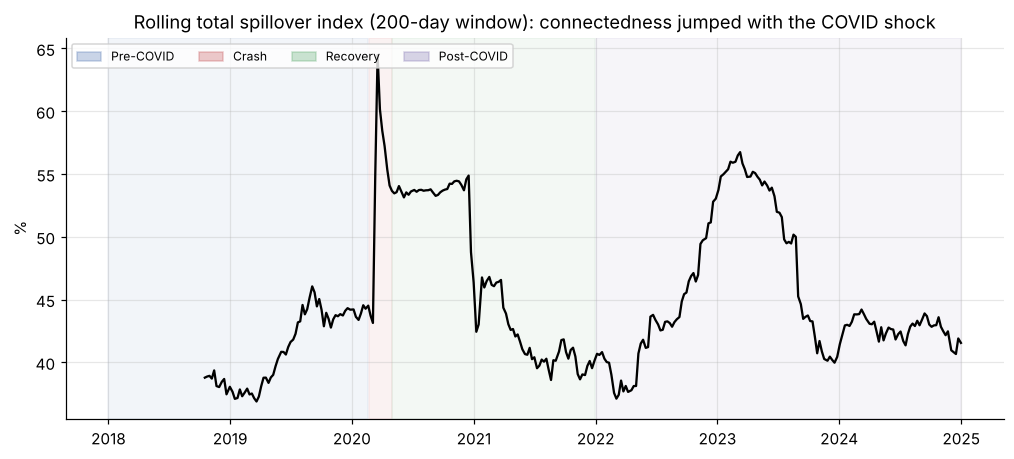

Pre-COVID     41.1
Crash         54.5
Recovery      46.5
Post-COVID    45.1


In [4]:
roll = S.rolling_total_spillover(r, window=200, step=5)
fig, ax = plt.subplots()
ax.plot(roll, color="k"); shade(ax)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, alpha=0.3, label=p) for p, c in D.PERIOD_COLORS.items()], ncol=4, fontsize=8, loc="upper left")
ax.set_title("Rolling total spillover index (200-day window): connectedness jumped with the COVID shock"); ax.set_ylabel("%")
plt.savefig(IMG / "rolling_spillover.png", bbox_inches="tight"); plt.show()
print(roll.groupby(pd.cut(roll.index, [pd.Timestamp(s) for s, _ in D.PERIODS.values()] + [roll.index[-1] + pd.Timedelta(days=1)],
                          labels=list(D.PERIODS), right=False), observed=True).mean().round(1).to_string())

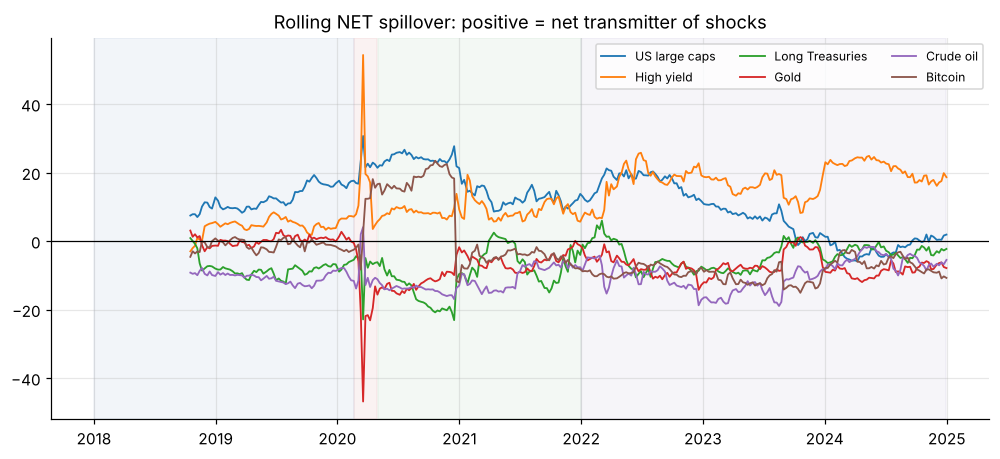

In [5]:
net = S.rolling_net_spillover(r, window=200, step=5)
net.columns = names
fig, ax = plt.subplots()
for c in ["US large caps", "High yield", "Long Treasuries", "Gold", "Crude oil", "Bitcoin"]: ax.plot(net[c], label=c, lw=1.2)
shade(ax); ax.axhline(0, color="k", lw=0.8); ax.legend(ncol=3, fontsize=8)
ax.set_title("Rolling NET spillover: positive = net transmitter of shocks"); plt.savefig(IMG / "net_spillover.png", bbox_inches="tight"); plt.show()

**Reading the results**
* US equities and high-yield credit are the main **net transmitters**. Their shocks explain a large share of other assets' variance.
* Treasuries, gold and the dollar are mostly **net receivers**.
* The total spillover index jumps when the crash enters the rolling window: markets became much more connected, which is when diversification is needed most and delivers least.
* A **second surge in 2022-23** coincides with the Fed's tightening cycle, when rates and inflation shocks hit stocks and bonds together. Connectedness is driven by the type of shock, not only by its size.